# Benchmarking optimization algorithms

This notebook demonstrates how to benchmark and compare optimization algorithms using the SMT-optim post-processing tools. Three types of profiles are covered:

- **Convergence profiles** show the best feasible objective value found as a function of the cost (iterations or budget).
- **Data profiles** show the fraction of problems an algorithm solves as a function of the cost.
- **Performance profiles** show the fraction of problems an algorithm solves within a given factor of the cost of the best algorithm.

A run *solves* a problem instance when it finds a feasible point $\boldsymbol{x}$ such that

$$
f(\boldsymbol{x}) \leq f_\star + \tau (f_0 - f_\star),
$$

where $f_0$ and $f_\star$ are the reference initial and best objective values of the problem, and $\tau \in [0, 1]$ is the tolerance. Let $t_{p,s}$ be the cost required by algorithm $s$ to solve instance $p$ ($t_{p,s} = \infty$ if the instance is never solved), and $P$ be the set of instances. The data profile and the performance profile of algorithm $s$ are

$$
d_s(\alpha) = \frac{1}{|P|} \left| \left\{ p \in P : t_{p,s} \leq \alpha \right\} \right|
\qquad \text{and} \qquad
\rho_s(r) = \frac{1}{|P|} \left| \left\{ p \in P : \frac{t_{p,s}}{\min_{s'} t_{p,s'}} \leq r \right\} \right|.
$$

In [1]:
import os
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from smt_optim.core import ObjectiveConfig, ConstraintConfig, Problem, DriverConfig, Driver
from smt_optim.surrogate_models import SmtGPX, SmtAutoModel
from smt_optim.acquisition_strategies import MFSEGO
from smt_optim.acquisition_functions import expected_improvement, probability_of_improvement

from smt_optim.benchmarks.registry import get_problem

from smt_optim.postprocessing.load_data import load_data
from smt_optim.postprocessing.profiles import (
    get_convergence_profile,
    get_data_profile,
    get_perf_profile,
    get_solve_table,
    get_data_profile_from_table,
    get_perf_profile_from_table,
)

In [2]:
# EXECUTE is set to False by default because generating the benchmark results can take a long time. The results are saved under: `examples/data/`.
EXECUTE = False


## Unconstrained problems example

This section illustrates how to use the SMT-optim post-processing tools to analyze optimization benchmark results. First, optimization results are generated to compare the **Expected Improvement** and the **Probability of Improvement** acquisition functions on unconstrained problems.

The benchmark results must be organized in the following directory structure. Each optimization run is logged in a `doe.csv` file, which is enabled with `log_doe=True` in the `DriverConfig`.

```
dir/
    algorithm_0/
        problem_0/
            instance_0/
                doe.csv
            instance_1/
                doe.csv
            ...
        problem_1/
            instance_0/
                doe.csv
            ...
    algorithm_1/
        problem_0/
            instance_0/
                doe.csv
            ...
    ...
```

An *instance* is one repetition of a problem, here with a different initial DOE controlled by the seed. All algorithms must be run on the same problems and instances, and for a given instance they must start from the same initial DOE (same seed) so that the comparison is fair. Each `doe.csv` file must contain at least the columns `iter`, `budget`, `fidelity`, `f0` (objective value), and `rscv` (relative sum of constraint violations).

The code cells below define the benchmark and run it only if `EXECUTE=True`. By default, the results already stored in `examples/data/` are used.

In [3]:


def benchmark_acq_func(problem, seed, path, acq_func):

    if os.path.isdir(path):
        return None

    obj_config = ObjectiveConfig(
        objective=[problem.objective],
        type="minimize",
        surrogate=SmtGPX,
    )

    prob_definition = Problem(
        obj_configs=[obj_config],
        design_space=problem.bounds,
    )

    driver_config = DriverConfig(
        max_iter = 20*problem.num_dim,
        nt_init = problem.num_dim+1,
        results_dir=path,
        log_doe=True,
        verbose = False,
        seed=seed,
    )

    # configure the optimizer. Note: if a single fidelity level is given to the MFSEGO acquisition strategy, it falls back to the SEGO framework.
    driver = Driver(prob_definition, driver_config, MFSEGO, strategy_kwargs={"acq_func": acq_func})

    # return the optimization data
    state = driver.optimize()


configurations = {
    "expected_improvement": partial(benchmark_acq_func, acq_func=expected_improvement),
    "probability_of_improvement": partial(benchmark_acq_func, acq_func=probability_of_improvement),
}


In [4]:

problem_list = ["RotatedHyperEllipsoid", "Sphere", "SumSquares"]
num_dims = [2]
num_doe = 5

if EXECUTE:
    for prob_name in problem_list:
        print(f"Solving for problem: {prob_name}")
        
        for n_dim in num_dims:

            problem = get_problem(prob_name)
            problem.set_dim(n_dim)

            for seed_id in range(num_doe):

                for config_name, config_method in configurations.items():
                
                    path = os.path.join(f"data", "unconstrained", config_name, f"{prob_name}_{n_dim}d", f"instance_{seed_id}")
                    config_method(problem, seed_id, path)



### Loading the results

The `load_data` method reads all the `doe.csv` files of a directory. It returns the nested dictionary `data[algorithm][problem][instance]`, whose values are pandas DataFrames, and a `ValidationReport`. The report lists the files with missing columns, the algorithms that were not run on all problem instances, and the instances for which the algorithms did not start from the same initial point. By default, these issues are reported as warnings. Use `strict=True` to raise an error instead.

In [5]:
unconstrained_dir = os.path.join("data", "unconstrained")

data, report = load_data(unconstrained_dir)
print(report.summary())

No issues found.


### Convergence profile

The convergence profile shows the best feasible objective value found so far as a function of the cost. The `get_convergence_profile` method returns, for each algorithm and problem, this value for every instance as well as statistics over the instances (`mean`, `std`, `min`, and `max`). The `metric_name` argument selects the cost: `"iter"`, `"budget"`, or any other column of the `doe.csv` files.

The figure below shows the average best objective value over the instances of two problems.

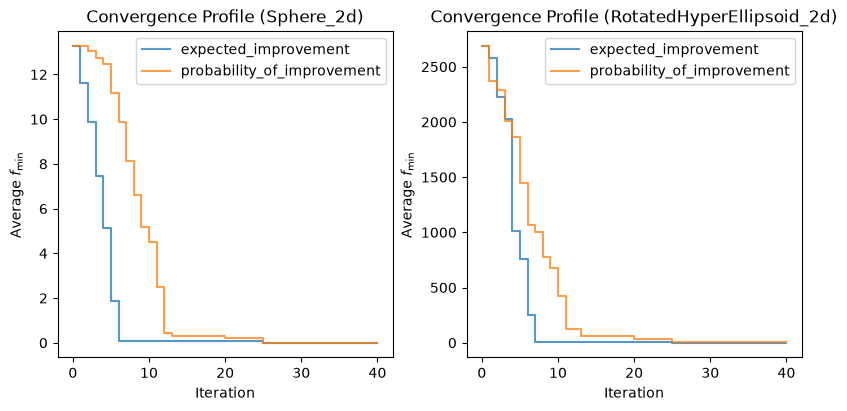

In [6]:
problems = ["Sphere_2d", "RotatedHyperEllipsoid_2d"]

conv_profile = get_convergence_profile(data, metric_name="iter")

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for i, prob_name in enumerate(problems):
    for algo, c_data in conv_profile.items():
        ax[i].step(c_data[prob_name]["iter"], c_data[prob_name]["mean"], where="post", label=algo, alpha=0.75)

    ax[i].set_title(f"Convergence Profile ({prob_name})")
    ax[i].set_xlabel("Iteration")
    ax[i].set_ylabel(r"Average $f_\min$")
    ax[i].legend()

plt.show()

### Data profile

The data profile shows the fraction of problem instances an algorithm solves as a function of the cost. An instance is solved when the algorithm finds a feasible point whose objective value is below the threshold $f_\star + \tau (f_0 - f_\star)$. The tolerance $\tau$ controls how demanding the threshold is: $\tau = 0$ requires reaching the best known value $f_\star$.

The `get_data_profile` method takes the loaded data, the cost metric, and the tolerance `tau`. It returns, for each algorithm, the `portion` of solved instances as a function of the cost. The curves are step functions and are plotted with `where="post"`. The figure below compares two tolerances.

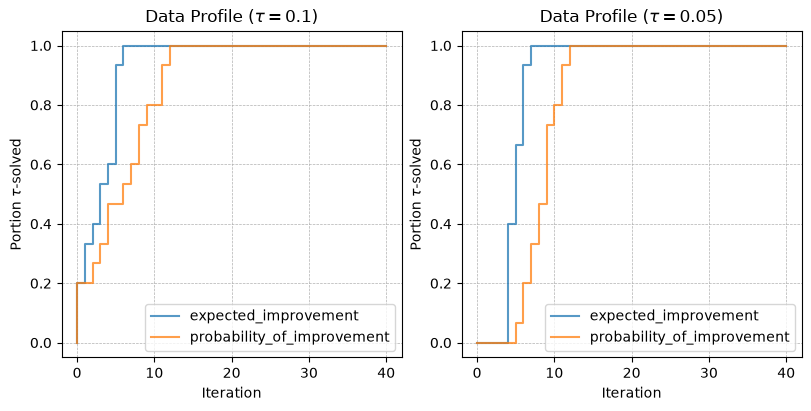

In [7]:
taus = [0.1, 0.05]

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for i, tau in enumerate(taus):
    data_profile = get_data_profile(data, "iter", tau=tau)

    for algo, a_data in data_profile.items():
        ax[i].step(a_data["iter"], a_data["portion"], where="post", label=algo, alpha=0.75)

    ax[i].set_title(rf"Data Profile ($\tau={tau}$)")
    ax[i].set_xlabel("Iteration")
    ax[i].set_ylabel(r"Portion $\tau$-solved")
    ax[i].set_ylim((-0.05, 1.05))
    ax[i].grid(linewidth=0.5, linestyle="--")
    ax[i].legend()

plt.show()

### Performance profile

The data profile measures the absolute cost of the algorithms, whereas the performance profile compares them relatively. For each problem instance, the cost of an algorithm is divided by the lowest cost among all algorithms. The profile shows the fraction of instances for which this ratio is lower than or equal to $r$. Its value at $r=1$ is the fraction of instances for which the algorithm is the cheapest (ties count for all the tied algorithms), and its value for large $r$ is the fraction of instances solved. The ratio is usually shown in log scale.

The `get_perf_profile` method takes the same arguments as `get_data_profile`. The `unsolved_by_all` argument sets how to handle the instances that no algorithm solves: they are counted as failures for all algorithms (`"keep"`, the default) or removed from the profile (`"drop"`).

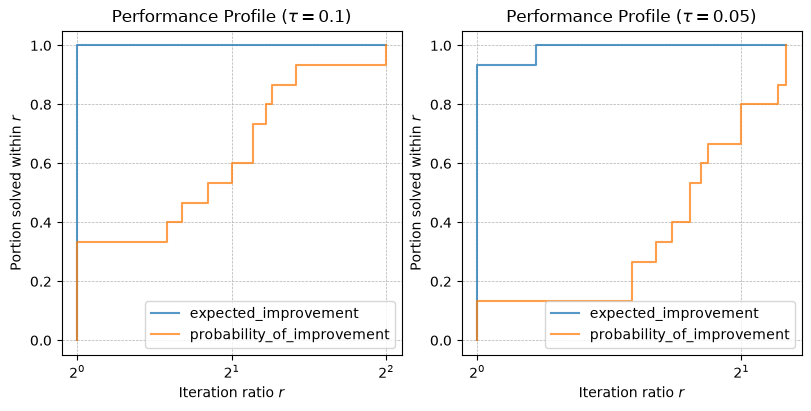

In [8]:
taus = [0.1, 0.05]

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for i, tau in enumerate(taus):
    perf_profile = get_perf_profile(data, "iter", tau=tau)

    for algo, p_data in perf_profile.items():
        ax[i].step(p_data["ratio"], p_data["portion"], where="post", label=algo, alpha=0.75)

    ax[i].set_xscale("log", base=2)
    ax[i].set_title(rf"Performance Profile ($\tau={tau}$)")
    ax[i].set_xlabel(r"Iteration ratio $r$")
    ax[i].set_ylabel(r"Portion solved within $r$")
    ax[i].set_ylim((-0.05, 1.05))
    ax[i].grid(linewidth=0.5, linestyle="--")
    ax[i].legend()

plt.show()

## Constrained & multi-fidelity problems example

The second benchmark compares the same two acquisition functions on constrained problems with two fidelity levels (`Rosenbrock`, `Branin1`, and `Gano`). A low-fidelity evaluation costs `LF_COST` units of budget and a high-fidelity evaluation costs 1 unit. Since the cost of an iteration depends on the fidelity level selected, the **budget** is the relevant cost metric in this example. Moreover, only feasible points evaluated at the highest fidelity level count towards solving a problem.

In [9]:
LF_COST = 0.2

def benchmark_acq_func_mf(problem, seed, path, acq_func):

    if os.path.isdir(path):
        return None

    obj_config = ObjectiveConfig(
        objective=problem.objective,
        type="minimize",
        surrogate=SmtAutoModel,
    )

    cstr_config = ConstraintConfig(
        constraint=problem.constraints[0],
        upper=0.,
        surrogate=SmtAutoModel,
    )

    prob_definition = Problem(
        obj_configs=[obj_config],
        cstr_configs=[cstr_config],
        design_space=problem.bounds,
        costs=[LF_COST, 1.],
    )

    driver_config = DriverConfig(
        max_iter = int(10*problem.num_dim/LF_COST),
        max_budget = 10*problem.num_dim,
        nt_init = problem.num_dim+1,
        results_dir=path,
        log_doe=True,
        verbose = False,
        seed=seed,
    )

    strategy_kwargs = {
        "acq_func": acq_func, 
        "n_start": 5,
        "sp_tol": 1e-4,
    }

    # configure the optimizer. Note: if a single fidelity level is given to the MFSEGO acquisition strategy, it falls back to the SEGO framework.
    driver = Driver(prob_definition, driver_config, MFSEGO, strategy_kwargs=strategy_kwargs)

    # return the optimization data
    state = driver.optimize()


configurations = {
    "expected_improvement": partial(benchmark_acq_func_mf, acq_func=expected_improvement),
    "probability_of_improvement": partial(benchmark_acq_func_mf, acq_func=probability_of_improvement),
}



In [10]:

problem_list = ["Rosenbrock", "Branin1", "Gano"]
num_doe = 5

if EXECUTE:
    for prob_name in problem_list:
        print(f"Solving for problem: {prob_name}")
        problem = get_problem(prob_name)
        # problem.set_dim(n_dim)

        for seed_id in range(num_doe):

            for config_name, config_method in configurations.items():
            
                path = os.path.join(f"data", "multifidelity", config_name, f"{prob_name}", f"instance_{seed_id}")
                config_method(problem, seed_id, path)




### Data profile

The results are loaded and validated as before. The `ctol` argument is the feasibility tolerance: a point is feasible if its `rscv` is lower than or equal to `ctol`. The data profile is computed with the budget as cost metric.

No issues found.


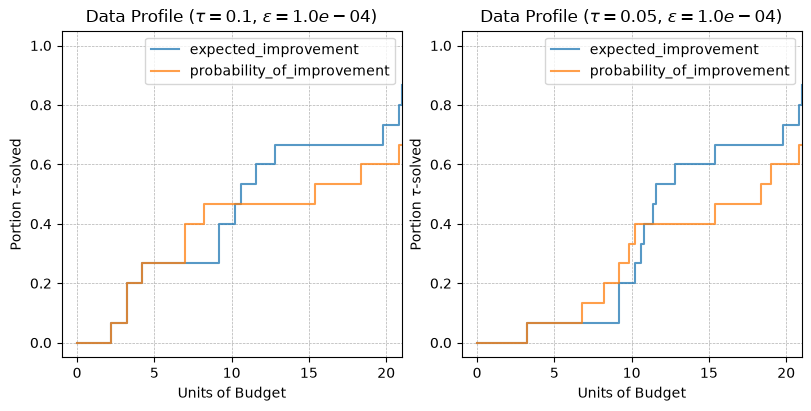

In [11]:
multifidelity_dir = os.path.join("data", "multifidelity")
taus = [0.1, 0.05]
ctol = 1e-4

data, report = load_data(multifidelity_dir)
print(report.summary())

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for i, tau in enumerate(taus):
    data_profile = get_data_profile(data, "budget", tau=tau, ctol=ctol)

    for algo, a_data in data_profile.items():
        ax[i].step(a_data["budget"], a_data["portion"], where="post", label=algo, alpha=0.75)

    ax[i].set_title(rf"Data Profile ($\tau={tau}$, $\epsilon={ctol:.1e}$)")
    ax[i].set_xlabel("Units of Budget")
    ax[i].set_ylabel(r"Portion $\tau$-solved")
    ax[i].set_xlim((-1, 21))
    ax[i].set_ylim((-0.05, 1.05))
    ax[i].grid(linewidth=0.5, linestyle="--")
    ax[i].legend()

plt.show()

### Performance profile

The performance profile compares the budget required by each algorithm to the lowest budget required by any algorithm, for each problem instance. Algorithms whose curve is the highest solve the most instances within a given factor of the best algorithm.

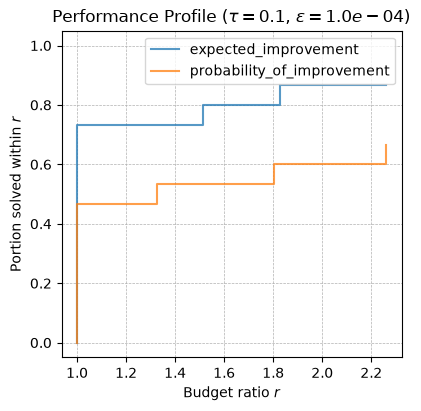

In [12]:
perf_profile = get_perf_profile(data, "budget", tau=0.1, ctol=ctol)

fig, ax = plt.subplots(layout="constrained", figsize=(4, 4))

for algo, p_data in perf_profile.items():
    ax.step(p_data["ratio"], p_data["portion"], where="post", label=algo, alpha=0.75)

ax.set_title(rf"Performance Profile ($\tau=0.1$, $\epsilon={ctol:.1e}$)")
ax.set_xlabel(r"Budget ratio $r$")
ax.set_ylabel(r"Portion solved within $r$")
ax.set_ylim((-0.05, 1.05))
ax.grid(linewidth=0.5, linestyle="--")
ax.legend()

plt.show()

## Solve table

The data and performance profiles are computed in two steps. First, `get_solve_table` builds a table with one row per algorithm, problem, and instance. For each row, the table records:

- `solved`: whether the instance was solved.
- `fmin`: the best feasible objective value found (`inf` if none).
- `n_dim`: the number of design variables.
- one column per cost metric (`idx`, `iter`, and `budget` by default): the cost at which the instance was solved (`inf` if unsolved).
- one `max_<metric>` column per cost metric: the cost at the end of the run.

Then, `get_data_profile_from_table` and `get_perf_profile_from_table` turn the table into profiles. The `get_data_profile` and `get_perf_profile` methods chain both steps. Building the table once is more efficient when several profiles are needed.

In [13]:
table = get_solve_table(data, tau=0.1, ctol=ctol)
table.head(10)

,algo,problem,instance,n_dim,solved,fmin,idx,max_idx,iter,max_iter,budget,max_budget
0,expected_improvement,Branin1,instance_0,2,True,5.576277,8.0,72.0,0.0,60.0,4.2,20.2
1,expected_improvement,Branin1,instance_1,2,True,5.576546,25.0,68.0,15.0,55.0,9.2,20.2
2,expected_improvement,Branin1,instance_2,2,True,5.577903,37.0,68.0,27.0,55.0,11.6,20.2
3,expected_improvement,Branin1,instance_3,2,True,5.575714,25.0,80.0,15.0,70.0,9.2,20.2
4,expected_improvement,Branin1,instance_4,2,True,5.748858,30.0,71.0,20.0,58.0,10.2,20.8
5,expected_improvement,Gano,instance_0,2,True,26.435519,6.0,68.0,0.0,54.0,2.2,21.0
6,expected_improvement,Gano,instance_1,2,True,26.638590,39.0,68.0,28.0,55.0,12.8,20.2
7,expected_improvement,Gano,instance_2,2,True,19.484669,32.0,69.0,22.0,56.0,10.6,20.4
8,expected_improvement,Gano,instance_3,2,True,24.430967,7.0,72.0,0.0,60.0,3.2,20.2
9,expected_improvement,Gano,instance_4,2,True,7.100442,7.0,72.0,0.0,59.0,3.2,21.0


algo
expected_improvement          0.866667
probability_of_improvement    0.666667
Name: solved, dtype: float64


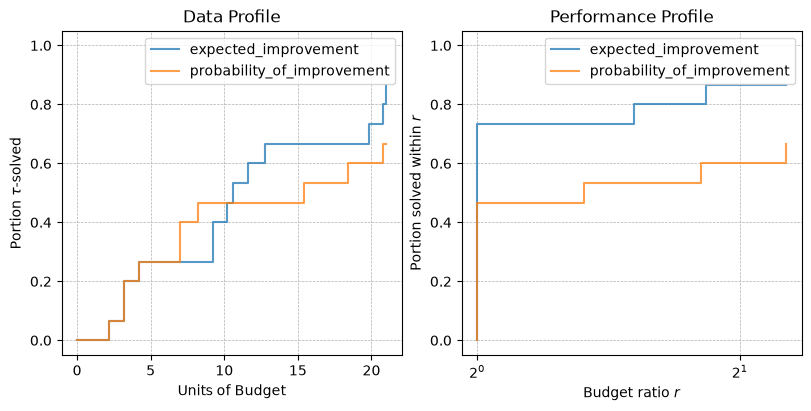

In [14]:
data_profile = get_data_profile_from_table(table, "budget")
perf_profile = get_perf_profile_from_table(table, "budget")

# fraction of instances solved by each algorithm
print(table.groupby("algo")["solved"].mean())

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for algo in data_profile:
    ax[0].step(data_profile[algo]["budget"], data_profile[algo]["portion"], where="post", label=algo, alpha=0.75)
    ax[1].step(perf_profile[algo]["ratio"], perf_profile[algo]["portion"], where="post", label=algo, alpha=0.75)

ax[0].set_title("Data Profile")
ax[0].set_xlabel("Units of Budget")
ax[0].set_ylabel(r"Portion $\tau$-solved")

ax[1].set_xscale("log", base=2)
ax[1].set_title("Performance Profile")
ax[1].set_xlabel(r"Budget ratio $r$")
ax[1].set_ylabel(r"Portion solved within $r$")

for a in ax:
    a.set_ylim((-0.05, 1.05))
    a.grid(linewidth=0.5, linestyle="--")
    a.legend()

plt.show()

## Custom cost metrics

Any quantity that accumulates along a run can be used as cost, such as the time or the number of high-fidelity evaluations. A cost metric must be cumulative: it must be non-decreasing along the rows of a `doe.csv` file. There are two ways to define one:

1. Add a column to the DataFrames returned by `load_data`, and use its name as `metric_name`.
2. Pass a function through `custom_metrics`. The function receives the DataFrame of an instance and returns one cost per row.

The code cell below computes a performance profile of the cumulative time, using the `time` column of the `doe.csv` files (option 1), and a data profile of the number of high-fidelity evaluations (option 2).

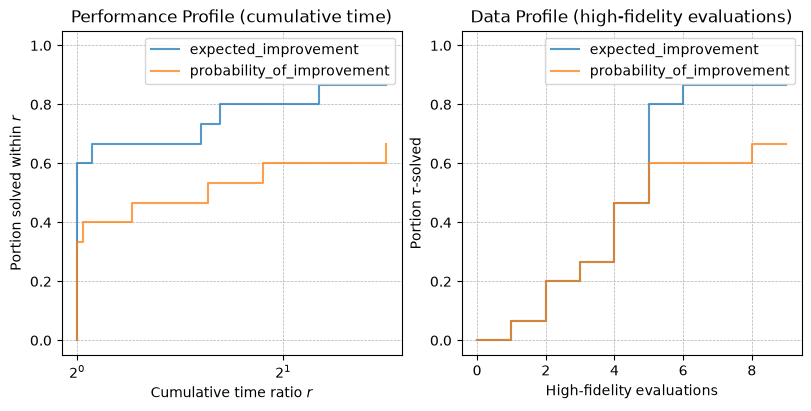

In [15]:
for a_data in data.values():
    for p_data in a_data.values():
        for i_data in p_data.values():
            i_data["cum_time"] = i_data["time"].cumsum()

hf_evals = {
    "hf_evals": lambda df: (df["fidelity"] == df["fidelity"].max()).cumsum().to_numpy(),
}

perf_time = get_perf_profile(data, "cum_time", tau=0.1, ctol=ctol)
data_hf = get_data_profile(data, "hf_evals", tau=0.1, ctol=ctol, custom_metrics=hf_evals)

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(8, 4))

for algo in perf_time:
    ax[0].step(perf_time[algo]["ratio"], perf_time[algo]["portion"], where="post", label=algo, alpha=0.75)
    ax[1].step(data_hf[algo]["hf_evals"], data_hf[algo]["portion"], where="post", label=algo, alpha=0.75)

ax[0].set_xscale("log", base=2)
ax[0].set_title("Performance Profile (cumulative time)")
ax[0].set_xlabel(r"Cumulative time ratio $r$")
ax[0].set_ylabel(r"Portion solved within $r$")

ax[1].set_title("Data Profile (high-fidelity evaluations)")
ax[1].set_xlabel("High-fidelity evaluations")
ax[1].set_ylabel(r"Portion $\tau$-solved")

for a in ax:
    a.set_ylim((-0.05, 1.05))
    a.grid(linewidth=0.5, linestyle="--")
    a.legend()

plt.show()

### Going further

The arguments of each method are documented in its docstring, which can be displayed in a notebook with `help(get_perf_profile)` or `get_perf_profile?`. In particular:

- `f0_method` sets the reference initial value $f_0$ of the problems (`"max_feasible"`, `"init_min"`, or `"init_max"`).
- `normalize_by_dim=True` expresses the cost of the data profile in units of $n+1$, where $n$ is the number of design variables.
- `unsolved_by_all` sets how the performance profile handles the instances that no algorithm solves.